# Simulasi Manual Decision Tree pada Wine Quality

Delapan baris data tetap dipakai untuk kedua simulasi, dengan fitur `alcohol` dan `volatile acidity`:

1. Regressor: MSE, MSE terbobot, variance reduction, dan prediksi rata-rata leaf.
2. Classifier: Gini, Gini terbobot, dan information gain.

Setiap simulasi membangun pohon kedalaman 2 secara manual, lalu hasilnya diverifikasi terhadap scikit-learn.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text

RANDOM_STATE = 42
QUALITY_THRESHOLD = 6
MAX_DEPTH_SIM = 2
SIM_FEATURES = ["alcohol", "volatile acidity"]

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Data

Delapan baris berikut dipakai apa adanya, tanpa pengambilan sampel acak, sehingga hasil perhitungan manual dapat diperiksa langsung. Kolom `target` diturunkan dari `quality >= 6`.

In [2]:
sample = pd.DataFrame({
    "alcohol": [9.3000, 9.3000, 9.7333, 10.0000, 10.3000, 10.5000, 10.5000, 12.7000],
    "volatile acidity": [0.15, 0.28, 0.22, 0.20, 0.19, 0.22, 0.32, 0.36],
    "quality": [5, 6, 5, 5, 6, 6, 4, 6],
})
sample.index = pd.RangeIndex(start=1, stop=9, name="No")
sample["target"] = (sample["quality"] >= QUALITY_THRESHOLD).astype(int)
sample["label"] = sample["target"].map({0: "buruk (0)", 1: "baik (1)"})

print(f"Baris: {len(sample)} | baik: {int(sample['target'].sum())} | "
      f"buruk: {int((1 - sample['target']).sum())}")
sample[["alcohol", "volatile acidity", "quality", "label"]]

Baris: 8 | baik: 4 | buruk: 4


,alcohol,volatile acidity,quality,label
No,,,,
1,9.3000,0.15,5,buruk (0)
2,9.3000,0.28,6,baik (1)
3,9.7333,0.22,5,buruk (0)
4,10.0000,0.20,5,buruk (0)
5,10.3000,0.19,6,baik (1)
6,10.5000,0.22,6,baik (1)
7,10.5000,0.32,4,buruk (0)
8,12.7000,0.36,6,baik (1)


### Helper bersama

Fungsi berikut dipakai oleh kedua simulasi: pemindaian kandidat split (ambang titik tengah, skor terbobot, gain), penghitung node untuk menggambar pohon, penghitung kedalaman node scikit-learn, dan pembanding split manual dengan split scikit-learn.

In [3]:
def count_nodes(node):
    if node["left"] is None:
        return 1
    return 1 + count_nodes(node["left"]) + count_nodes(node["right"])


def node_depths(tree):
    depths = {0: 0}
    stack = [0]
    while stack:
        node = stack.pop()
        for child in (tree.children_left[node], tree.children_right[node]):
            if child != -1:
                depths[int(child)] = depths[node] + 1
                stack.append(int(child))
    return depths


def compare_splits(tree, model):
    rows = []
    stack = [(tree, 0)]
    while stack:
        node, node_id = stack.pop()
        if node["left"] is None:
            continue
        feature = SIM_FEATURES[model.tree_.feature[node_id]]
        threshold = float(model.tree_.threshold[node_id])
        rows.append({
            "manual": f"{node['feature']} <= {node['threshold']:.4f}",
            "sklearn": f"{feature} <= {threshold:.4f}",
            "cocok": node["feature"] == feature and abs(node["threshold"] - threshold) < 1e-6,
        })
        stack.append((node["left"], int(model.tree_.children_left[node_id])))
        stack.append((node["right"], int(model.tree_.children_right[node_id])))
    return pd.DataFrame(rows)

In [4]:
def candidate_thresholds(values):
    unique = np.unique(values)
    return [float((a + b) / 2.0) for a, b in zip(unique[:-1], unique[1:])]


def score_candidates(x, y, score):
    rows = []
    for idx in range(x.shape[1]):
        for threshold in candidate_thresholds(x[:, idx]):
            mask = x[:, idx] <= threshold
            y_left, y_right = y[mask], y[~mask]
            weighted = mask.mean() * score(y_left) + (1 - mask.mean()) * score(y_right)
            rows.append({
                "feature": SIM_FEATURES[idx],
                "feature_idx": idx,
                "threshold": threshold,
                "n_left": int(mask.sum()),
                "n_right": int((~mask).sum()),
                "positive_left": int(y_left.sum()),
                "positive_right": int(y_right.sum()),
                "mean_left": float(y_left.mean()),
                "mean_right": float(y_right.mean()),
                "score_left": score(y_left),
                "score_right": score(y_right),
                "score_weighted": weighted,
                "gain": score(y) - weighted,
            })
    return rows


def best_split(x, y, score):
    rows = score_candidates(x, y, score)
    if not rows:
        return None
    return min(rows, key=lambda r: (round(r["score_weighted"], 12), r["feature_idx"], r["threshold"]))


def apply_split(df, split):
    mask = df[split["feature"]] <= split["threshold"]
    return df[mask].copy(), df[~mask].copy()

## 2. Simulasi manual: regressor

Aturan split mengikuti scikit-learn dengan `criterion="squared_error"`: kandidat ambang adalah titik tengah dua nilai unik bertetangga, `x <= ambang` masuk ke anak kiri, split terbaik dipilih dari MSE terbobot terkecil (variance reduction terbesar), prediksi leaf adalah rata-rata target di leaf, dan tie-break memakai urutan fitur lalu ambang terkecil.

In [5]:
def mse(y):
    return float(np.mean((y - y.mean()) ** 2))


def reg_candidate_table(rows):
    table = pd.DataFrame(rows)
    table["_sort"] = table["score_weighted"].round(12)
    table = table.sort_values(["_sort", "feature_idx", "threshold"], ascending=[True, True, True])
    table.insert(0, "rank", range(1, len(table) + 1))
    table["kiri (n, mean)"] = [f"{row.n_left} ({row.mean_left:.3f})" for row in table.itertuples()]
    table["kanan (n, mean)"] = [f"{row.n_right} ({row.mean_right:.3f})" for row in table.itertuples()]
    table = table.rename(columns={
        "score_left": "MSE kiri",
        "score_right": "MSE kanan",
        "score_weighted": "MSE terbobot",
        "gain": "variance reduction",
    })
    return table[[
        "rank", "feature", "threshold", "kiri (n, mean)", "kanan (n, mean)",
        "MSE kiri", "MSE kanan", "MSE terbobot", "variance reduction",
    ]].round(4)


def build_reg_tree(df, depth=0):
    y = df["quality"].to_numpy(dtype=float)
    node = {
        "n": len(df),
        "mean": float(y.mean()),
        "mse": mse(y),
        "feature": None,
        "threshold": None,
        "gain": None,
        "left": None,
        "right": None,
    }
    if depth >= MAX_DEPTH_SIM or len(np.unique(y)) == 1:
        return node

    split = best_split(df[SIM_FEATURES].to_numpy(), y, mse)
    if split is None:
        return node

    node["feature"] = split["feature"]
    node["threshold"] = split["threshold"]
    node["gain"] = split["gain"]
    left, right = apply_split(df, split)
    node["left"] = build_reg_tree(left, depth + 1)
    node["right"] = build_reg_tree(right, depth + 1)
    return node


def reg_rules(tree, path=""):
    if tree["left"] is None:
        condition = path or "seluruh data"
        return [f"JIKA {condition} MAKA prediksi = {tree['mean']:.4f} "
                f"(n={tree['n']}, MSE={tree['mse']:.4f})"]

    condition = f"{tree['feature']} <= {tree['threshold']:.4f}"
    left_path = f"{path} DAN ({condition})" if path else condition
    right_path = f"{path} DAN BUKAN ({condition})" if path else f"BUKAN ({condition})"
    return reg_rules(tree["left"], left_path) + reg_rules(tree["right"], right_path)


def reg_predict(tree, df):
    predictions = []
    for _, row in df.iterrows():
        node = tree
        while node["left"] is not None:
            node = node["left"] if row[node["feature"]] <= node["threshold"] else node["right"]
        predictions.append(node["mean"])
    return np.asarray(predictions)

In [ ]:
x_reg_sample = sample[SIM_FEATURES].to_numpy()
y_reg_sample = sample["quality"].to_numpy(dtype=float)
root_reg = best_split(x_reg_sample, y_reg_sample, mse)

print(f"Mean parent = {y_reg_sample.mean():.4f} | MSE parent = {mse(y_reg_sample):.4f}")
print(f"Split terpilih: {root_reg['feature']} <= {root_reg['threshold']:.4f} "
      f"(MSE terbobot = {root_reg['score_weighted']:.4f})")
reg_candidate_table(score_candidates(x_reg_sample, y_reg_sample, mse))

Mean parent = 5.3750 | MSE parent = 0.4844
Split terpilih: alcohol <= 11.6000 (MSE terbobot = 0.4286)


,rank,feature,threshold,"kiri (n, mean)","kanan (n, mean)",MSE kiri,MSE kanan,MSE terbobot,variance reduction
4,1,alcohol,11.6000,7 (5.286),1 (6.000),0.4898,0.0000,0.4286,0.0558
10,2,volatile acidity,0.3400,7 (5.286),1 (6.000),0.4898,0.0000,0.4286,0.0558
9,3,volatile acidity,0.3000,6 (5.500),2 (5.000),0.2500,1.0000,0.4375,0.0469
5,4,volatile acidity,0.1700,1 (5.000),7 (5.429),0.0000,0.5306,0.4643,0.0201
2,5,alcohol,10.1500,4 (5.250),4 (5.500),0.1875,0.7500,0.4688,0.0156
0,6,alcohol,9.5166,2 (5.500),6 (5.333),0.2500,0.5556,0.4792,0.0052
6,7,volatile acidity,0.1950,2 (5.500),6 (5.333),0.2500,0.5556,0.4792,0.0052
1,8,alcohol,9.8666,3 (5.333),5 (5.400),0.2222,0.6400,0.4833,0.0010
3,9,alcohol,10.4000,5 (5.400),3 (5.333),0.2400,0.8889,0.4833,0.0010
7,10,volatile acidity,0.2100,3 (5.333),5 (5.400),0.2222,0.6400,0.4833,0.0010


In [7]:
left_reg, right_reg = apply_split(sample, root_reg)
for name, part in [("kiri", left_reg), ("kanan", right_reg)]:
    part_y = part["quality"].to_numpy(dtype=float)
    print(f"\nAnak {name}: n={len(part)}, MSE={mse(part_y):.4f}")
    rows = score_candidates(part[SIM_FEATURES].to_numpy(), part_y, mse)
    if rows:
        display(reg_candidate_table(rows))
    else:
        print("Tidak ada kandidat split: node hanya berisi satu nilai.")


Anak kiri: n=7, MSE=0.4898


,rank,feature,threshold,"kiri (n, mean)","kanan (n, mean)",MSE kiri,MSE kanan,MSE terbobot,variance reduction
8,1,volatile acidity,0.3000,6 (5.500),1 (4.000),0.2500,0.0000,0.2143,0.2755
3,2,alcohol,10.4000,5 (5.400),2 (5.000),0.2400,1.0000,0.4571,0.0327
7,3,volatile acidity,0.2500,5 (5.400),2 (5.000),0.2400,1.0000,0.4571,0.0327
0,4,alcohol,9.5166,2 (5.500),5 (5.200),0.2500,0.5600,0.4714,0.0184
5,5,volatile acidity,0.1950,2 (5.500),5 (5.200),0.2500,0.5600,0.4714,0.0184
4,6,volatile acidity,0.1700,1 (5.000),6 (5.333),0.0000,0.5556,0.4762,0.0136
1,7,alcohol,9.8666,3 (5.333),4 (5.250),0.2222,0.6875,0.4881,0.0017
2,8,alcohol,10.1500,4 (5.250),3 (5.333),0.1875,0.8889,0.4881,0.0017
6,9,volatile acidity,0.2100,3 (5.333),4 (5.250),0.2222,0.6875,0.4881,0.0017



Anak kanan: n=1, MSE=0.0000
Tidak ada kandidat split: node hanya berisi satu nilai.


In [8]:
tree_reg = build_reg_tree(sample)
print("\n".join(reg_rules(tree_reg)))

pred_manual = reg_predict(tree_reg, sample)
pd.DataFrame({
    "alcohol": sample["alcohol"],
    "volatile acidity": sample["volatile acidity"],
    "quality": sample["quality"],
    "prediksi manual": pred_manual,
})

JIKA alcohol <= 11.6000 DAN (volatile acidity <= 0.3000) MAKA prediksi = 5.5000 (n=6, MSE=0.2500)
JIKA alcohol <= 11.6000 DAN BUKAN (volatile acidity <= 0.3000) MAKA prediksi = 4.0000 (n=1, MSE=0.0000)
JIKA BUKAN (alcohol <= 11.6000) MAKA prediksi = 6.0000 (n=1, MSE=0.0000)


,alcohol,volatile acidity,quality,prediksi manual
No,,,,
1,9.3000,0.15,5,5.5
2,9.3000,0.28,6,5.5
3,9.7333,0.22,5,5.5
4,10.0000,0.20,5,5.5
5,10.3000,0.19,6,5.5
6,10.5000,0.22,6,5.5
7,10.5000,0.32,4,4.0
8,12.7000,0.36,6,6.0


**Grafik 1. Pohon regressor hasil perhitungan manual.**

Kotak biru adalah node internal: baris pertama kondisi split (fitur <= ambang), diikuti MSE node, rata-rata quality, dan jumlah baris. Kotak kuning adalah daun: nilai prediksi (rata-rata quality di daun), MSE, dan jumlah baris. Cabang kiri diberi label ya (kondisi terpenuhi) dan cabang kanan tidak. Pohon dibangun rekursif sampai kedalaman 2 dari 8 baris sampel, lalu strukturnya dibandingkan dengan DecisionTreeRegressor pada sel berikutnya.

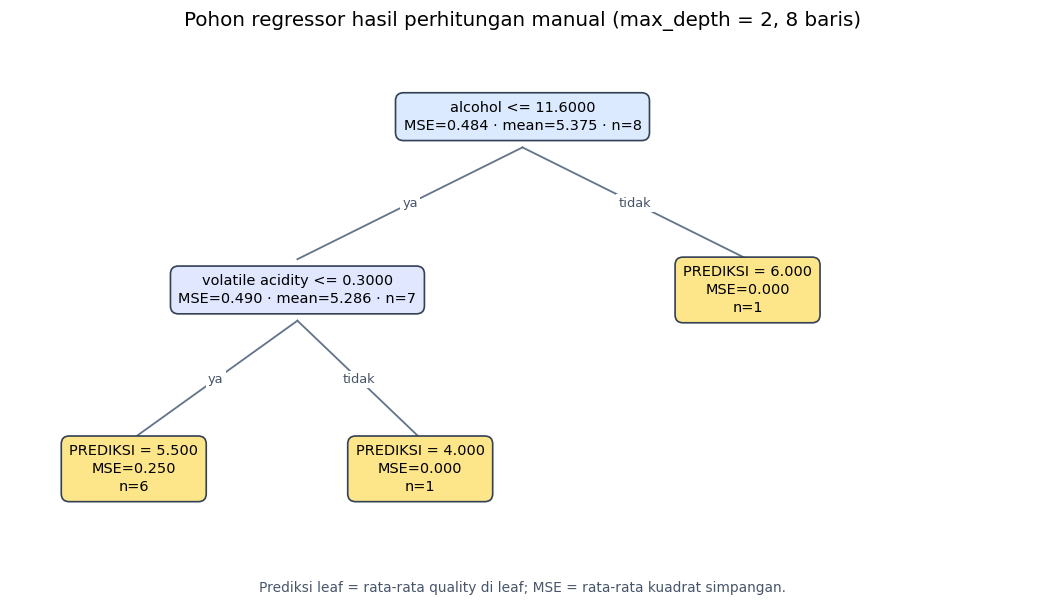

In [9]:
def plot_reg_tree(tree):
    nodes = []

    def flatten(node):
        nodes.append(node)
        if node["left"] is not None:
            flatten(node["left"])
            flatten(node["right"])

    flatten(tree)
    positions = [
        (0.50, 0.87),
        (0.28, 0.56),
        (0.12, 0.24),
        (0.40, 0.24),
        (0.72, 0.56),
        (0.60, 0.24),
        (0.88, 0.24),
    ]

    fig, ax = plt.subplots(figsize=(12, 6.6))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    for idx, node in enumerate(nodes):
        x_pos, y_pos = positions[idx]
        if node["left"] is None:
            color = "#fde68a"
            text = (f"PREDIKSI = {node['mean']:.3f}\n"
                    f"MSE={node['mse']:.3f}\nn={node['n']}")
        else:
            color = "#dbeafe" if idx == 0 else "#e0e7ff"
            text = (f"{node['feature']} <= {node['threshold']:.4f}\n"
                    f"MSE={node['mse']:.3f} · mean={node['mean']:.3f} · n={node['n']}")
        ax.text(x_pos, y_pos, text, ha="center", va="center", fontsize=9.5, linespacing=1.35,
                bbox=dict(boxstyle="round,pad=0.55", facecolor=color,
                          edgecolor="#334155", linewidth=1.1))

    for idx, node in enumerate(nodes):
        if node["left"] is None:
            continue
        px, py = positions[idx]
        left_idx = idx + 1
        right_idx = left_idx + count_nodes(node["left"])
        for child_idx, label in [(left_idx, "ya"), (right_idx, "tidak")]:
            cx, cy = positions[child_idx]
            ax.plot([px, cx], [py - 0.055, cy + 0.055], color="#64748b", linewidth=1.2)
            ax.text((px + cx) / 2, (py + cy) / 2, label, fontsize=8.5, color="#475569",
                    ha="center", va="center",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

    ax.set_title("Pohon regressor hasil perhitungan manual (max_depth = 2, 8 baris)",
                 fontsize=13, pad=12)
    ax.text(0.5, 0.02, "Prediksi leaf = rata-rata quality di leaf; MSE = rata-rata kuadrat simpangan.",
            ha="center", fontsize=9, color="#475569")
    plt.show()


plot_reg_tree(tree_reg)

In [10]:
model_reg = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=MAX_DEPTH_SIM,
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
)
model_reg.fit(sample[SIM_FEATURES], sample["quality"])
print(export_text(model_reg, feature_names=SIM_FEATURES, decimals=4))

|--- alcohol <= 11.6000
|   |--- volatile acidity <= 0.3000
|   |   |--- value: [5.5000]
|   |--- volatile acidity >  0.3000
|   |   |--- value: [4.0000]
|--- alcohol >  11.6000
|   |--- value: [6.0000]



In [11]:
def describe_reg_tree(model):
    tree = model.tree_
    depths = node_depths(tree)
    rows = []
    for node in range(tree.node_count):
        rows.append({
            "node": node,
            "depth": depths[node],
            "n": int(tree.n_node_samples[node]),
            "mse": round(float(tree.impurity[node]), 4),
            "feature": None if tree.feature[node] < 0 else SIM_FEATURES[tree.feature[node]],
            "threshold": None if tree.threshold[node] < 0 else round(float(tree.threshold[node]), 4),
            "prediksi (mean)": round(float(tree.value[node].ravel()[0]), 4),
        })
    return pd.DataFrame(rows)


describe_reg_tree(model_reg)

,node,depth,n,mse,feature,threshold,prediksi (mean)
0,0,0,8,0.4844,alcohol,11.6,5.3750
1,1,1,7,0.4898,volatile acidity,0.3,5.2857
2,2,2,6,0.2500,None,NaN,5.5000
3,3,2,1,0.0000,None,NaN,4.0000
4,4,1,1,0.0000,None,NaN,6.0000


In [12]:
comparison_reg = compare_splits(tree_reg, model_reg)
pred_sklearn = model_reg.predict(sample[SIM_FEATURES])

print(f"Split cocok: {int(comparison_reg['cocok'].sum())}/{len(comparison_reg)}")
print("Selisih prediksi leaf manual vs sklearn: maksimum "
      f"{np.max(np.abs(pred_manual - pred_sklearn)):.2e}")
comparison_reg

Split cocok: 2/2
Selisih prediksi leaf manual vs sklearn: maksimum 0.00e+00


,manual,sklearn,cocok
0,alcohol <= 11.6000,alcohol <= 11.6000,True
1,volatile acidity <= 0.3000,volatile acidity <= 0.3000,True


## 3. Simulasi manual: classifier

Aturan split sama, tetapi impurity diganti Gini dan split dipilih dari information gain terbesar. Simulasi memakai `alcohol` dan `volatile acidity` seperti bagian regressor.

In [13]:
def gini(y):
    p = float(np.mean(y))
    return 1.0 - (1.0 - p) ** 2 - p ** 2

In [14]:
def candidate_table(rows):
    table = pd.DataFrame(rows)
    table["_sort"] = table["gain"].round(12)
    table = table.sort_values(["_sort", "feature_idx", "threshold"], ascending=[False, True, True])
    table.insert(0, "rank", range(1, len(table) + 1))
    table["kiri (n baik/buruk)"] = [
        f"{row.n_left} ({row.positive_left}/{row.n_left - row.positive_left})"
        for row in table.itertuples()
    ]
    table["kanan (n baik/buruk)"] = [
        f"{row.n_right} ({row.positive_right}/{row.n_right - row.positive_right})"
        for row in table.itertuples()
    ]
    table = table.rename(columns={
        "score_left": "gini kiri",
        "score_right": "gini kanan",
        "score_weighted": "gini terbobot",
        "gain": "information gain",
    })
    return table[[
        "rank", "feature", "threshold", "kiri (n baik/buruk)", "kanan (n baik/buruk)",
        "gini kiri", "gini kanan", "gini terbobot", "information gain",
    ]].round(4)


def build_clf_tree(df, depth=0):
    y = df["target"].to_numpy()
    node = {
        "n": len(df),
        "positive": int(y.sum()),
        "gini": gini(y),
        "prediction": int(round(y.mean())),
        "feature": None,
        "threshold": None,
        "gain": None,
        "left": None,
        "right": None,
    }
    if depth >= MAX_DEPTH_SIM or len(np.unique(y)) == 1:
        return node

    split = best_split(df[SIM_FEATURES].to_numpy(), y, gini)
    if split is None:
        return node

    node["feature"] = split["feature"]
    node["threshold"] = split["threshold"]
    node["gain"] = split["gain"]
    left, right = apply_split(df, split)
    node["left"] = build_clf_tree(left, depth + 1)
    node["right"] = build_clf_tree(right, depth + 1)
    return node


def clf_rules(tree, path=""):
    if tree["left"] is None:
        condition = path or "seluruh data"
        label = "baik" if tree["prediction"] else "buruk"
        return [f"JIKA {condition} MAKA {label} "
                f"(n={tree['n']}, baik={tree['positive']}, buruk={tree['n'] - tree['positive']})"]

    condition = f"{tree['feature']} <= {tree['threshold']:.4f}"
    left_path = f"{path} DAN ({condition})" if path else condition
    right_path = f"{path} DAN BUKAN ({condition})" if path else f"BUKAN ({condition})"
    return clf_rules(tree["left"], left_path) + clf_rules(tree["right"], right_path)

In [15]:
x_clf = sample[SIM_FEATURES].to_numpy()
y_clf = sample["target"].to_numpy()
root_clf = best_split(x_clf, y_clf, gini)

print(f"Gini parent = {gini(y_clf):.4f}")
print(f"Split terpilih: {root_clf['feature']} <= {root_clf['threshold']:.4f} "
      f"(IG = {root_clf['gain']:.4f})")
candidate_table(score_candidates(x_clf, y_clf, gini))

Gini parent = 0.5000
Split terpilih: alcohol <= 10.1500 (IG = 0.1250)


,rank,feature,threshold,kiri (n baik/buruk),kanan (n baik/buruk),gini kiri,gini kanan,gini terbobot,information gain
2,1,alcohol,10.1500,4 (1/3),4 (3/1),0.3750,0.3750,0.3750,0.1250
4,2,alcohol,11.6000,7 (3/4),1 (1/0),0.4898,0.0000,0.4286,0.0714
5,3,volatile acidity,0.1700,1 (0/1),7 (4/3),0.0000,0.4898,0.4286,0.0714
10,4,volatile acidity,0.3400,7 (3/4),1 (1/0),0.4898,0.0000,0.4286,0.0714
1,5,alcohol,9.8666,3 (1/2),5 (3/2),0.4444,0.4800,0.4667,0.0333
3,6,alcohol,10.4000,5 (2/3),3 (2/1),0.4800,0.4444,0.4667,0.0333
7,7,volatile acidity,0.2100,3 (1/2),5 (3/2),0.4444,0.4800,0.4667,0.0333
8,8,volatile acidity,0.2500,5 (2/3),3 (2/1),0.4800,0.4444,0.4667,0.0333
0,9,alcohol,9.5166,2 (1/1),6 (3/3),0.5000,0.5000,0.5000,0.0000
6,10,volatile acidity,0.1950,2 (1/1),6 (3/3),0.5000,0.5000,0.5000,0.0000


In [16]:
left_clf, right_clf = apply_split(sample, root_clf)
for name, part in [("kiri", left_clf), ("kanan", right_clf)]:
    part_y = part["target"].to_numpy()
    print(f"\nAnak {name}: n={len(part)}, Gini={gini(part_y):.4f}")
    rows = score_candidates(part[SIM_FEATURES].to_numpy(), part_y, gini)
    if rows:
        display(candidate_table(rows))
    else:
        print("Tidak ada kandidat split: node hanya berisi satu nilai.")


Anak kiri: n=4, Gini=0.3750


,rank,feature,threshold,kiri (n baik/buruk),kanan (n baik/buruk),gini kiri,gini kanan,gini terbobot,information gain
4,1,volatile acidity,0.2500,3 (0/3),1 (1/0),0.0000,0.0000,0.0000,0.3750
0,2,alcohol,9.5166,2 (1/1),2 (0/2),0.5000,0.0000,0.2500,0.1250
3,3,volatile acidity,0.2100,2 (0/2),2 (1/1),0.0000,0.5000,0.2500,0.1250
1,4,alcohol,9.8666,3 (1/2),1 (0/1),0.4444,0.0000,0.3333,0.0417
2,5,volatile acidity,0.1750,1 (0/1),3 (1/2),0.0000,0.4444,0.3333,0.0417



Anak kanan: n=4, Gini=0.3750


,rank,feature,threshold,kiri (n baik/buruk),kanan (n baik/buruk),gini kiri,gini kanan,gini terbobot,information gain
3,1,volatile acidity,0.270,2 (2/0),2 (1/1),0.0000,0.5000,0.2500,0.1250
0,2,alcohol,10.400,1 (1/0),3 (2/1),0.0000,0.4444,0.3333,0.0417
1,3,alcohol,11.600,3 (2/1),1 (1/0),0.4444,0.0000,0.3333,0.0417
2,4,volatile acidity,0.205,1 (1/0),3 (2/1),0.0000,0.4444,0.3333,0.0417
4,5,volatile acidity,0.340,3 (2/1),1 (1/0),0.4444,0.0000,0.3333,0.0417


In [17]:
tree_clf = build_clf_tree(sample)
print("\n".join(clf_rules(tree_clf)))

JIKA alcohol <= 10.1500 DAN (volatile acidity <= 0.2500) MAKA buruk (n=3, baik=0, buruk=3)
JIKA alcohol <= 10.1500 DAN BUKAN (volatile acidity <= 0.2500) MAKA baik (n=1, baik=1, buruk=0)
JIKA BUKAN (alcohol <= 10.1500) DAN (volatile acidity <= 0.2700) MAKA baik (n=2, baik=2, buruk=0)
JIKA BUKAN (alcohol <= 10.1500) DAN BUKAN (volatile acidity <= 0.2700) MAKA buruk (n=2, baik=1, buruk=1)


**Grafik 2. Pohon classifier hasil perhitungan manual.**

Node internal menampilkan kondisi split, Gini, jumlah baris, dan komposisi kelas [B = buruk, G = baik]. Daun berwarna hijau berarti prediksi baik (1) dan merah berarti prediksi buruk (0). Label ya dan tidak pada cabang mengikuti aturan x <= ambang. Struktur ini adalah hasil perhitungan Gini dan information gain manual yang diverifikasi terhadap DecisionTreeClassifier pada sel berikutnya.

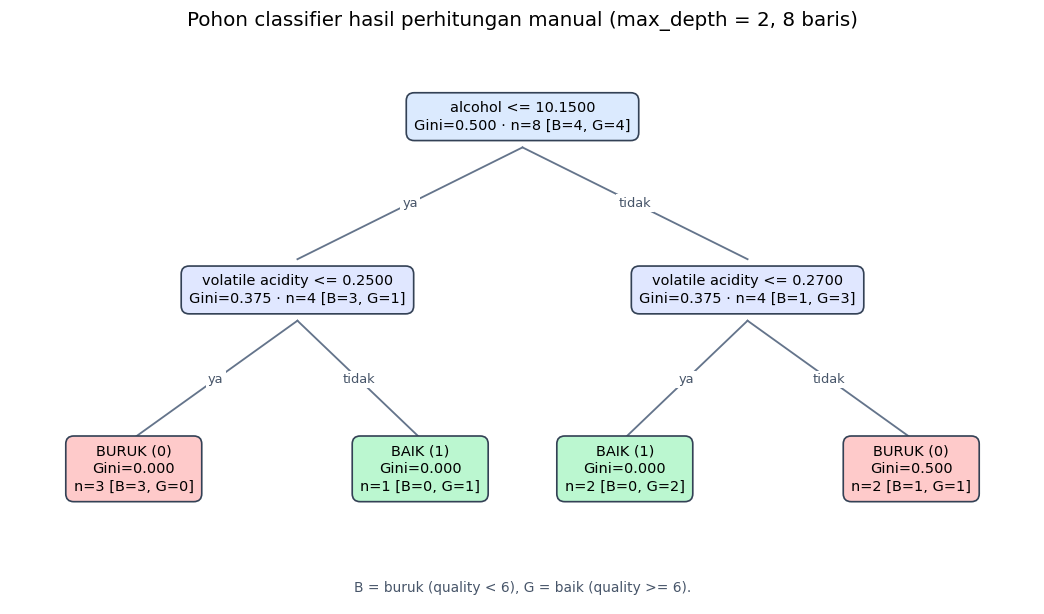

In [18]:
def plot_clf_tree(tree):
    nodes = []

    def flatten(node):
        nodes.append(node)
        if node["left"] is not None:
            flatten(node["left"])
            flatten(node["right"])

    flatten(tree)
    positions = [
        (0.50, 0.87),
        (0.28, 0.56),
        (0.12, 0.24),
        (0.40, 0.24),
        (0.72, 0.56),
        (0.60, 0.24),
        (0.88, 0.24),
    ]

    fig, ax = plt.subplots(figsize=(12, 6.6))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    for idx, node in enumerate(nodes):
        x_pos, y_pos = positions[idx]
        negative = node["n"] - node["positive"]
        if node["left"] is None:
            color = "#bbf7d0" if node["prediction"] == 1 else "#fecaca"
            label = "BAIK (1)" if node["prediction"] == 1 else "BURUK (0)"
            text = f"{label}\nGini={node['gini']:.3f}\nn={node['n']} [B={negative}, G={node['positive']}]"
        else:
            color = "#dbeafe" if idx == 0 else "#e0e7ff"
            text = (f"{node['feature']} <= {node['threshold']:.4f}\n"
                    f"Gini={node['gini']:.3f} · n={node['n']} [B={negative}, G={node['positive']}]")
        ax.text(x_pos, y_pos, text, ha="center", va="center", fontsize=9.5, linespacing=1.35,
                bbox=dict(boxstyle="round,pad=0.55", facecolor=color,
                          edgecolor="#334155", linewidth=1.1))

    for idx, node in enumerate(nodes):
        if node["left"] is None:
            continue
        px, py = positions[idx]
        left_idx = idx + 1
        right_idx = left_idx + count_nodes(node["left"])
        for child_idx, label in [(left_idx, "ya"), (right_idx, "tidak")]:
            cx, cy = positions[child_idx]
            ax.plot([px, cx], [py - 0.055, cy + 0.055], color="#64748b", linewidth=1.2)
            ax.text((px + cx) / 2, (py + cy) / 2, label, fontsize=8.5, color="#475569",
                    ha="center", va="center",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

    ax.set_title("Pohon classifier hasil perhitungan manual (max_depth = 2, 8 baris)",
                 fontsize=13, pad=12)
    ax.text(0.5, 0.02, "B = buruk (quality < 6), G = baik (quality >= 6).",
            ha="center", fontsize=9, color="#475569")
    plt.show()


plot_clf_tree(tree_clf)

In [19]:
model_clf = DecisionTreeClassifier(
    criterion="gini",
    max_depth=MAX_DEPTH_SIM,
    min_samples_leaf=1,
    random_state=RANDOM_STATE,
)
model_clf.fit(sample[SIM_FEATURES], sample["target"])
print(export_text(model_clf, feature_names=SIM_FEATURES, decimals=4))

|--- alcohol <= 10.1500
|   |--- volatile acidity <= 0.2500
|   |   |--- class: 0
|   |--- volatile acidity >  0.2500
|   |   |--- class: 1
|--- alcohol >  10.1500
|   |--- volatile acidity <= 0.2700
|   |   |--- class: 1
|   |--- volatile acidity >  0.2700
|   |   |--- class: 0



In [20]:
def describe_clf_tree(model):
    tree = model.tree_
    depths = node_depths(tree)
    rows = []
    for node in range(tree.node_count):
        values = np.asarray(tree.value[node][0], dtype=float)
        counts = values * tree.n_node_samples[node] if abs(values.sum() - 1) < 1e-9 else values
        rows.append({
            "node": node,
            "depth": depths[node],
            "n": int(tree.n_node_samples[node]),
            "gini": round(float(tree.impurity[node]), 4),
            "feature": None if tree.feature[node] < 0 else SIM_FEATURES[tree.feature[node]],
            "threshold": None if tree.threshold[node] < 0 else round(float(tree.threshold[node]), 4),
            "prediksi": ["buruk", "baik"][int(np.argmax(counts))],
        })
    return pd.DataFrame(rows)


describe_clf_tree(model_clf)

,node,depth,n,gini,feature,threshold,prediksi
0,0,0,8,0.500,alcohol,10.15,buruk
1,1,1,4,0.375,volatile acidity,0.25,buruk
2,2,2,3,0.000,None,NaN,buruk
3,3,2,1,0.000,None,NaN,baik
4,4,1,4,0.375,volatile acidity,0.27,baik
5,5,2,2,0.000,None,NaN,baik
6,6,2,2,0.500,None,NaN,buruk


In [21]:
comparison_clf = compare_splits(tree_clf, model_clf)
print(f"Split cocok: {int(comparison_clf['cocok'].sum())}/{len(comparison_clf)}")
comparison_clf

Split cocok: 3/3


,manual,sklearn,cocok
0,alcohol <= 10.1500,alcohol <= 10.1500,True
1,volatile acidity <= 0.2700,volatile acidity <= 0.2700,True
2,volatile acidity <= 0.2500,volatile acidity <= 0.2500,True
